## HuggingFace Transformers: API, Models and Fine-Tuning Techniques

### Day 3

In [1]:
import sys
import torch
import transformers
import PIL

print("Python version:", sys.version)
print("Torch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("PIL version:", PIL.__version__)

Python version: 3.14.8 (main, Sep 30 2026, 17:55:09) [Clang 21.0.0 (clang-2100.3.34.2)]
Torch version: 2.14.1
Transformers version: 5.19.0
PIL version: 12.3.0


In [2]:
torch.accelerator.get_memory_info()

(19069190144, 19069665280)

##### Image Segmentation using Vision Transformers (ViT)

Fetching image...
Image fetched successfully.


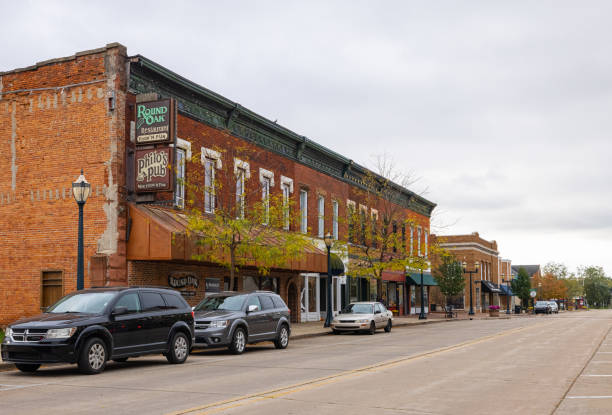

In [3]:
from PIL import Image
import requests

print("Fetching image...")
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/segmentation_input.jpg"
image = Image.open(requests.get(url, stream=True).raw)
print("Image fetched successfully.")
image

In [ ]:
print(type(image))

In [4]:
from transformers import pipeline
semantic_segmentation = pipeline("image-segmentation", 
                                 "nvidia/segformer-b1-finetuned-cityscapes-1024-1024",
                                 use_fast=True)

results = semantic_segmentation(image)
results

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/transformers/image_processing_base.py:417: UserWarning: The following named arguments are not valid for `SegformerImageProcessor.__init__` and were ignored: 'reduce_labels'
  image_processor = cls(**image_processor_dict)
Device set to use mps:0


[{'score': None,
  'label': 'road',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sidewalk',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'building',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'wall',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'pole',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'traffic sign',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'vegetation',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'terrain',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sky',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=612x415>}]

In [9]:
results[-1]

{'score': None,
 'label': 'car',
 'mask': <PIL.Image.Image image mode=L size=612x415>}

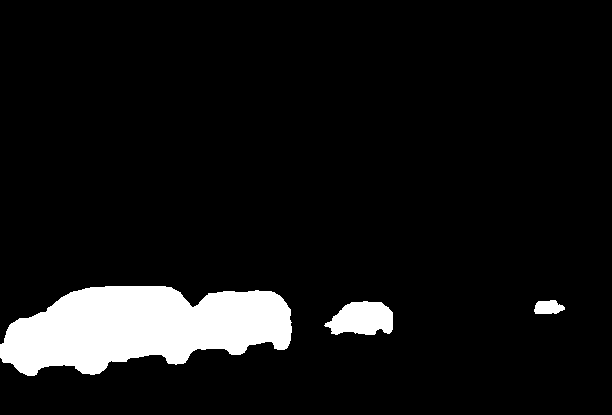

In [10]:
results[-1]["mask"]

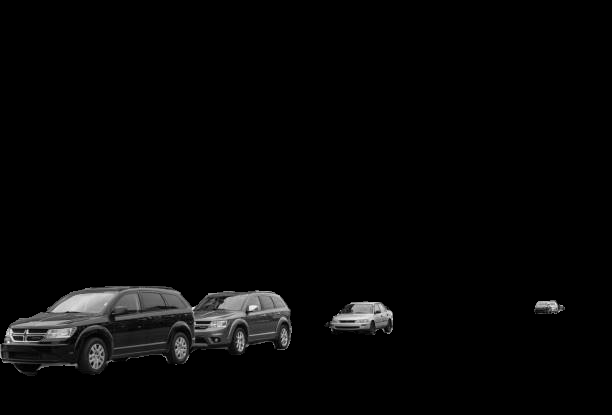

In [11]:
Image.composite(image, results[-1]["mask"], results[-1]["mask"])

--- 

##### Image Classification using Vision Transformers (ViT)

In [ ]:
!pip install matplotlib

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Device set to use mps:0


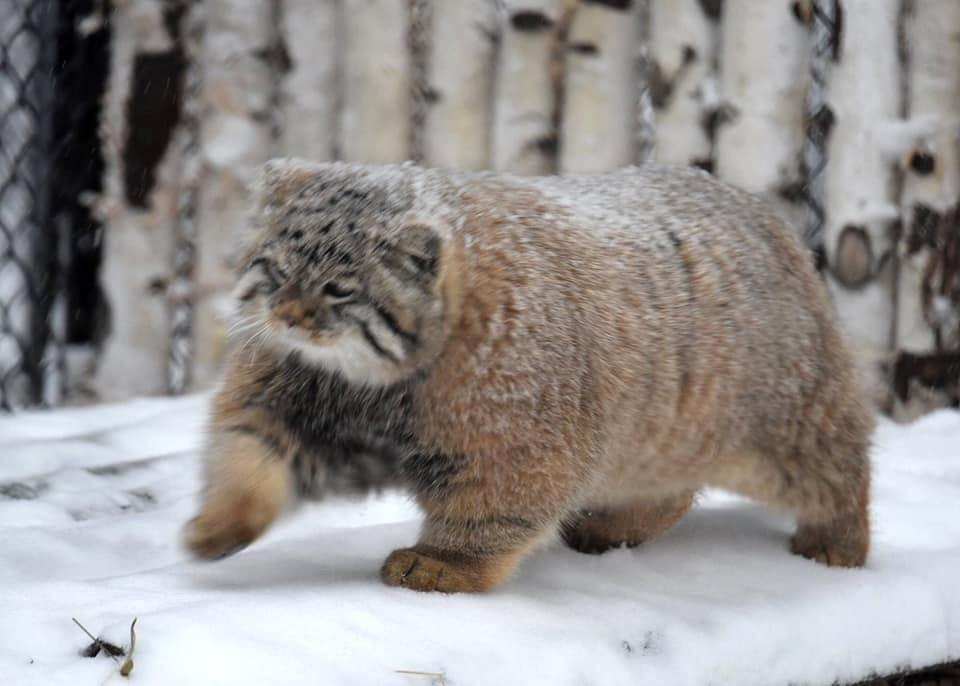

In [12]:
from transformers import pipeline
from PIL import Image
import requests

import matplotlib.pyplot as plt

# Load image classification pipeline
classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224",
    use_fast=True
)

# Load a sample image
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
response = requests.get(url, stream=True).raw
image = Image.open(response)

image

In [13]:

# Classify
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")


lynx, catamount: 0.433
cougar, puma, catamount, mountain lion, painter, panther, Felis concolor: 0.035
snow leopard, ounce, Panthera uncia: 0.032
Egyptian cat: 0.024
tiger cat: 0.023


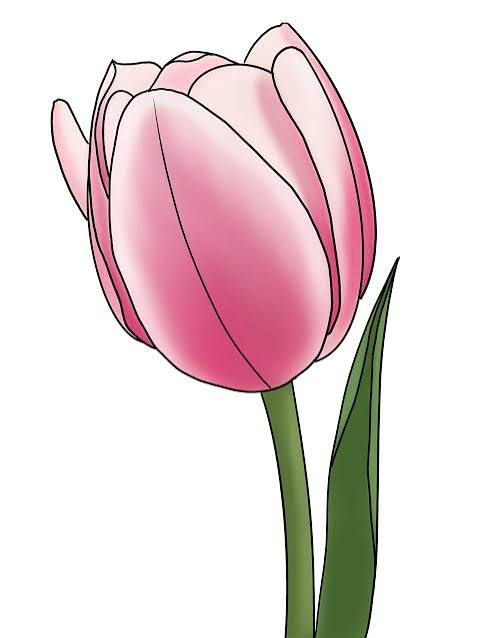

In [14]:
image = Image.open("../../tulip2.jpeg")
image

In [15]:
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

vase: 0.328
daisy: 0.278
pot, flowerpot: 0.020
pinwheel: 0.009
goblet: 0.007


In [ ]:

print("---")
# Try with your own images
image = Image.open("../../tulip2.jpeg")
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

---

#### Image Enhancement

(532, 432)


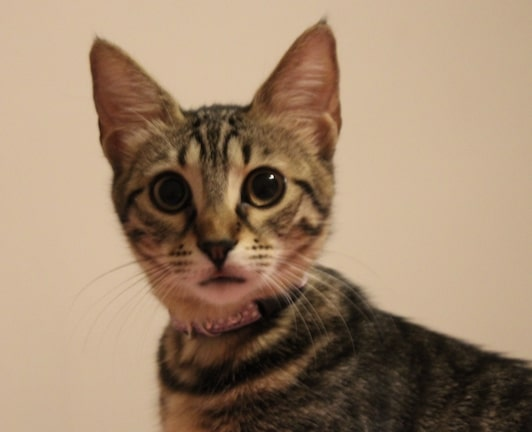

In [16]:
from PIL import Image
import requests

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/cat.jpg"
image = Image.open(requests.get(url, stream=True).raw)

print(image.size)
image

`self.pad_size` attribute is deprecated and will be removed in v5. Use `self.size_divisor` instead
Device set to use mps:0


(1072, 880)


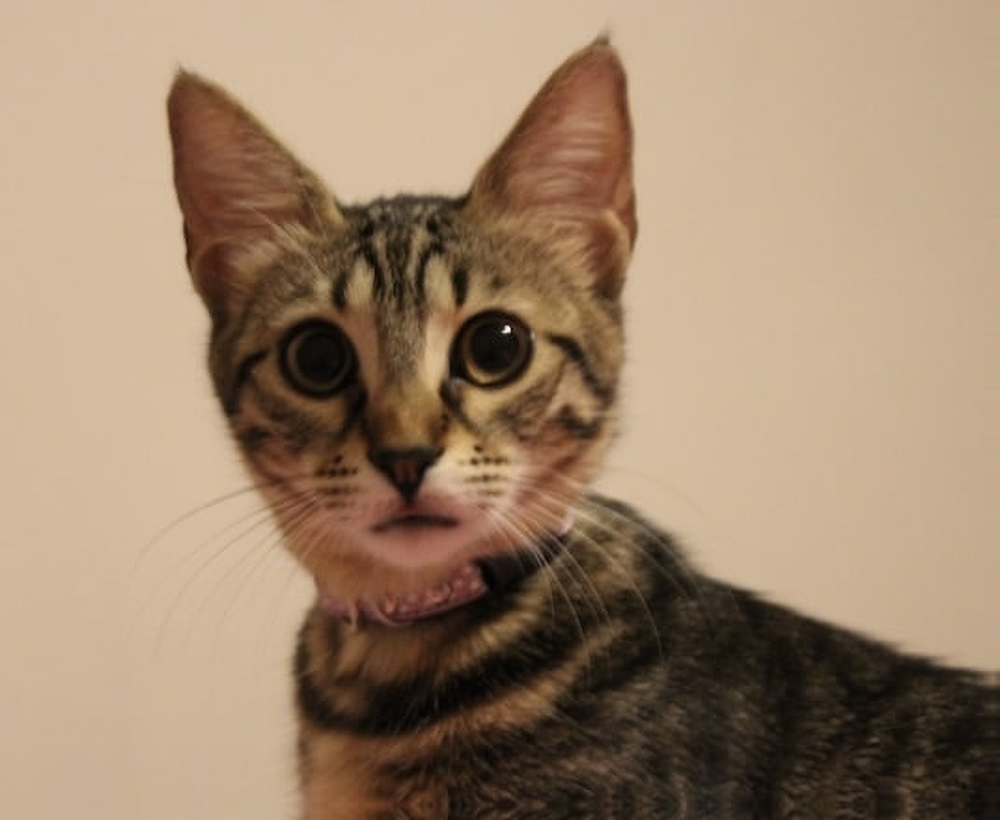

In [17]:
from transformers import pipeline
pipe = pipeline(task="image-to-image", model="caidas/swin2SR-lightweight-x2-64")

upscaled = pipe(image)
print(upscaled.size)
upscaled

(2160, 1776)


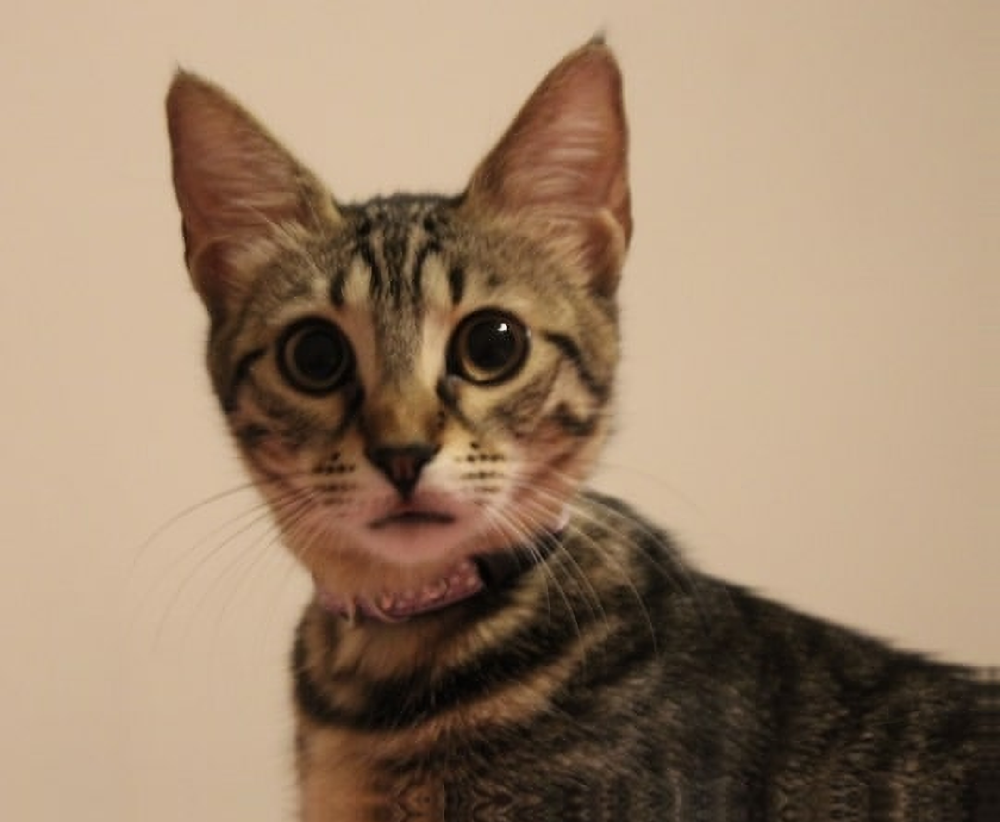

In [18]:
upscaled = pipe(upscaled)
print(upscaled.size)
upscaled

---

### Text-to-Text Generation

In [19]:
from transformers import pipeline

grammar_pipeline = pipeline(
    "text2text-generation",
    model="t5-base")

incorrect_text = "He have been working here since five years."
input_text = f"correct grammar: {incorrect_text}"
result = grammar_pipeline(input_text, num_beams=5)

print("Original:", incorrect_text)
print("Corrected:", result[0]['generated_text'])

Device set to use mps:0


Original: He have been working here since five years.
Corrected:                                                         


In [ ]:
!pip install protobuf

In [20]:
from transformers import pipeline

# 1. Initialize the text2text-generation pipeline with a dedicated grammar model
grammar_pipeline = pipeline(
    "text2text-generation", 
    model="AventIQ-AI/t5-small-grammar-correction"
)

# Other models you can try:
# - AventIQ-AI/t5-base-grammar-correction
# - vennify/t5-base-grammar-correction
# - pszemraj/flan-t5-large-grammar-synthesis
# - Sajid030/t5-base-grammar-synthesis

# 2. Define the grammatically incorrect text
# Note: T5 models usually expect a task prefix like "correct grammar: "
incorrect_text = "She dont like to eat vegetables but she like fruits."
input_text = f"correct grammar: {incorrect_text}"

# 3. Generate the correction
result = grammar_pipeline(input_text, num_beams=5)

# 4. Print the corrected output
print("Original:", incorrect_text)
print("Corrected:", result[0]['generated_text'])


You set `add_prefix_space`. The tokenizer needs to be converted from the slow tokenizers
Device set to use mps:0


Original: She dont like to eat vegetables but she like fruits.
Corrected: She doesn't like to eat vegetables, but she likes fruits.


---

#### Working with ```datasets```

In [21]:
from datasets import load_dataset

In [23]:
dataset = load_dataset("ethz/food101")
dataset

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00008.parquet:   0%|          | 0.00/490M [00:00<?, ?B/s]

data/train-00001-of-00008.parquet:   0%|          | 0.00/464M [00:00<?, ?B/s]

data/train-00002-of-00008.parquet:   0%|          | 0.00/472M [00:00<?, ?B/s]

data/train-00003-of-00008.parquet:   0%|          | 0.00/464M [00:00<?, ?B/s]

...

data/validation-00001-of-00003.parquet:   0%|          | 0.00/413M [00:00<?, ?B/s]

data/validation-00002-of-00003.parquet:   0%|          | 0.00/426M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/75750 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 25250
    })
})

In [26]:
dataset.keys()

dict_keys(['train', 'validation'])

In [25]:
dataset["train"]

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [27]:
dataset.column_names

{'train': ['image', 'label'], 'validation': ['image', 'label']}

In [32]:
d = dataset["train"]
d

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [33]:
d.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', '

In [35]:
d.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [38]:
d.num_rows, d.num_columns

(75750, 2)

In [43]:
len(d.features["label"].names) # Number of classes in the dataset

101

In [45]:
lbl = d.features["label"]
lbl.num_classes

101

In [46]:
d.features["label"].num_classes

101

In [52]:
d.features["label"].names[-1]

'waffles'

In [54]:
lbl.str2int("baklava")

2

In [56]:
lbl.int2str(2)
d.features["label"].int2str(2)

'baklava'

In [ ]:
dataset.keys() # Identify the splits in the dataset

In [ ]:
v = dataset["validation"]

In [ ]:
v.column_names

In [ ]:
v.features

In [ ]:
v.num_rows

In [ ]:
v.features["label"].num_classes  # Fetch the number of classes in the label feature

In [58]:
train_dataset = dataset["train"]
train_dataset

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [59]:
train_dataset[0]

{'image': <PIL.Image.Image image mode=RGB size=384x512>, 'label': 6}

In [60]:
train_dataset.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

Idx: 49777 , Label: shrimp_and_grits


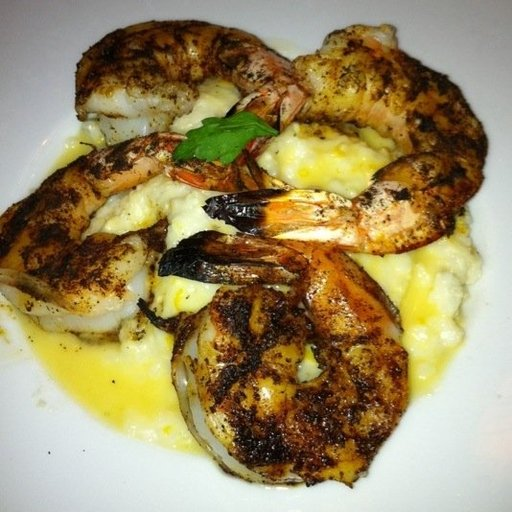

In [64]:
from random import randint

idx = randint(0, len(train_dataset) - 1)

print("Idx:", idx, ", Label:", train_dataset.features["label"].int2str(train_dataset[idx]["label"]))
train_dataset[idx]["image"]

In [ ]:
train_dataset.features["label"].int2str(train_dataset[0]["label"])

In [72]:
dataset2 = load_dataset("ariG23498/flickr8k")
dataset2

DatasetDict({
    train: Dataset({
        features: ['image', 'caption'],
        num_rows: 40455
    })
})

In [77]:
dataset_dict = dataset2["train"].train_test_split(test_size=0.15, seed=42)
ndataset_dict = dataset_dict["train"].train_test_split(test_size=0.1, seed=42)

train_dataset = ndataset_dict["train"]
validation_dataset = ndataset_dict["test"]
test_dataset = dataset_dict["test"]

dataset_dict = {
    "train": train_dataset,
    "validation": validation_dataset,
    "test": test_dataset
}
dataset_dict

{'train': Dataset({
     features: ['image', 'caption'],
     num_rows: 30947
 }),
 'validation': Dataset({
     features: ['image', 'caption'],
     num_rows: 3439
 }),
 'test': Dataset({
     features: ['image', 'caption'],
     num_rows: 6069
 })}

In [66]:
dataset2["train"].features

{'image': Image(mode=None, decode=True), 'caption': Value('string')}

In [67]:
from datasets import Dataset

d = Dataset.from_csv("reviews_simple.csv")
d

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})

In [69]:
d = load_dataset("csv", data_files="reviews_simple.csv")
d

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4
    })
})

In [ ]:
load_datase

Signature:
load_dataset(
    path: str,
    name: Optional[str] = None,
    data_dir: Optional[str] = None,
    data_files: Union[str, collections.abc.Sequence[str], collections.abc.Mapping[str, Union[str, collections.abc.Sequence[str]]], NoneType] = None,
    split: Union[str, datasets.splits.Split, list[str], list[datasets.splits.Split], NoneType] = None,
    cache_dir: Optional[str] = None,
    features: Optional[datasets.features.features.Features] = None,
    download_config: Optional[datasets.download.download_config.DownloadConfig] = None,
    download_mode: Union[datasets.download.download_manager.DownloadMode, str, NoneType] = None,
    verification_mode: Union[datasets.utils.info_utils.VerificationMode, str, NoneType] = None,
    keep_in_memory: Optional[bool] = None,
    save_infos: bool = False,
    revision: Union[datasets.utils.version.Version, str, NoneType] = None,
    token: Union[bool, str, NoneType] = None,
    streaming: bool = False,
    num_proc: Optional[int] = N

---
## Model Fine-tuning examples

#### A Skeletal example

In [70]:
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer,
    pipeline
)

# ==========================================
# 1. Prepare Your Custom Dataset
# ==========================================
# Sample dictionary (you can also load a CSV via pandas: pd.read_csv("data.csv"))
raw_data = {
    "text": [
        "I absolutely love this product! Highly recommended.",
        "Worst experience ever, totally disappointed.",
        "It's okay, nothing extraordinary.",
        "Great quality and fast delivery!",
        "Poor customer service and cheap quality.",
        "Fantastic service, will definitely buy again!"
    ],
    "label": [1, 0, 0, 1, 0, 1]  # 1: Positive, 0: Negative
}

# Convert dict to Hugging Face Dataset
#df = pd.DataFrame(raw_data)
dataset = Dataset.from_dict(raw_data)
dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 6
})

In [79]:
# Split into train and test/validation sets
dataset_split = dataset.train_test_split(test_size=0.33, seed=42)
train_dataset = dataset_split["train"]
eval_dataset = dataset_split["test"]

print(train_dataset)
print(eval_dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})
Dataset({
    features: ['text', 'label'],
    num_rows: 2
})


In [80]:

# ==========================================
# 2. Load Tokenizer & Model
# ==========================================
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Define label mappings
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, 
    num_labels=2, 
    id2label=id2label, 
    label2id=label2id
)

# ==========================================
# 3. Tokenize Data
# ==========================================
def preprocess_function(examples):
    # Truncate and pad inputs to fit model context
    return tokenizer(examples["text"], truncation=True, max_length=128)

tokenized_train = train_dataset.map(preprocess_function, batched=True)
tokenized_eval = eval_dataset.map(preprocess_function, batched=True)

print(tokenized_train)
print(tokenized_eval)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/4 [00:00<?, ? examples/s]

Map:   0%|          | 0/2 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 4
})
Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 2
})


In [103]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [98]:
model.num_parameters(only_trainable=True), model.num_parameters()

(66955010, 66955010)

In [99]:
for param in model.parameters():
    param.requires_grad = False  # Freeze all parameters

model.num_parameters(only_trainable=True), model.num_parameters()

(0, 66955010)

In [105]:
for name, param in model.named_parameters():
    if "layer.4" in name or "layer.5" in name:
        param.requires_grad = True  # Unfreeze last two layers

model.num_parameters(only_trainable=True), model.num_parameters()

(14175744, 66955010)

In [87]:
from transformers import Trainer, TrainingArguments
# ==========================================
# 4. Set Training Arguments & Trainer
# ==========================================
training_args = TrainingArguments(
    output_dir="./custom_classification_model",
    eval_strategy="epoch",       # Evaluate at the end of every epoch
    save_strategy="epoch",       # Save checkpoint at the end of every epoch
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    num_train_epochs=30,
    weight_decay=0.01,
    logging_steps=1
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_eval,
    processing_class=tokenizer
)


In [88]:

# ==========================================
# 5. Fine-Tune & Save Model
# ==========================================
print("Starting training...")
trainer.train()


Starting training...


/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.150600,0.490933
2,0.138000,0.460578
3,0.128100,0.413087
4,0.108200,0.387739
5,0.072000,0.364958
6,0.073700,0.351070
7,0.061500,0.334976
8,0.045500,0.334340
9,0.040300,0.327977
10,0.047900,0.313215


/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/envs/hf4_env/lib/python3.11/site-packages

TrainOutput(global_step=60, training_loss=0.04533282774500549, metrics={'train_runtime': 35.005, 'train_samples_per_second': 3.428, 'train_steps_per_second': 1.714, 'total_flos': 319784579568.0, 'train_loss': 0.04533282774500549, 'epoch': 30.0})

In [92]:

# Save final model and tokenizer locally
trainer.save_model("../../final_saved_model")
tokenizer.save_pretrained("../../final_saved_model")
print("Model saved successfully!")

# ==========================================
# 6. Test with Inference Pipeline
# ==========================================
classifier = pipeline("text-classification", model="../../final_saved_model")

test_text = "The quality can't get any better than this."
prediction = classifier(test_text)

print(f"\nText: {test_text}")
print(f"Prediction: {prediction}")

Device set to use mps:0


Model saved successfully!

Text: The quality can't get any better than this.
Prediction: [{'label': 'NEGATIVE', 'score': 0.668811023235321}]


---

#### Finetuning ModernBERT with custom dataset

In [ ]:
from datasets import load_dataset

# Dataset id from huggingface.co/dataset
dataset_id = "cornell-movie-review-data/rotten_tomatoes"

# Load raw dataset
raw_dataset = load_dataset(dataset_id)

print(f"Train dataset size: {len(raw_dataset['train'])}")
print(f"Test dataset size: {len(raw_dataset['test'])}")

In [ ]:
raw_dataset["train"].features

In [ ]:
from random import randrange

random_id = randrange(len(raw_dataset['train']))
raw_dataset['train'][random_id]


In [ ]:
from transformers import AutoTokenizer

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.model_max_length = 512 # set model_max_length to 512 as prompts are not longer than 1024 tokens

# Tokenize helper function
def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, return_tensors="pt")

# Tokenize dataset
raw_dataset =  raw_dataset.rename_column("label", "labels") # to match Trainer
tokenized_dataset = raw_dataset.map(tokenize, batched=True,remove_columns=["text"])

print(tokenized_dataset["train"].features.keys())
# dict_keys(['input_ids', 'attention_mask','labels'])

In [ ]:
from transformers import AutoModelForSequenceClassification

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Prepare model labels - useful for inference
labels = tokenized_dataset["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

# Download the model from huggingface.co/models
model = AutoModelForSequenceClassification.from_pretrained(
    model_id, num_labels=num_labels, label2id=label2id, id2label=id2label,
)

In [ ]:
!pip install scikit-learn

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

# Metric helper method
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    score = f1_score(
            labels, predictions, labels=labels, pos_label=1, average="weighted"
        )
    return {"f1": float(score) if score == 1 else score}

In [ ]:
from transformers import Trainer, TrainingArguments

# Define training args
training_args = TrainingArguments(
    output_dir= "modernbert-rotten-tomatoes",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
		num_train_epochs=5,
    bf16=True, # bfloat16 training 
    optim="adamw_torch_fused", # improved optimizer 
    # logging & evaluation strategies
    logging_strategy="steps",
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # push to hub parameters
    #report_to="tensorboard",
    push_to_hub=False,

)

# Create a Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    compute_metrics=compute_metrics,
)

In [ ]:
# Start training
trainer.train()

In [ ]:
# Save processor and create model card
tokenizer.save_pretrained("modernbert-rotten-tomatoes")
trainer.create_model_card()
trainer.push_to_hub()

---

### Finetuning an Image Classifier (ViT) with custom Image dataset

#### The `Trainer` API

`Trainer` is a complete training and evaluation loop for Transformers’ PyTorch models. Plug a model, preprocessor, dataset, and training arguments into `Trainer` and let it handle the rest to start training faster.

The Trainer simplifies the overhead of implementing our training loop for our training workflow using PyTorch models.

Trainer contains all the necessary components of a training loop.

 1. calculate the loss from a training step
 2. calculate the gradients with the backward method
 3. update the weights based on the gradients
 4. repeat until the predetermined number of epochs is reached

Manually coding this training loop everytime can be inconvenient or a barrier if you’re just getting started with machine learning. Trainer abstracts this process, allowing you to focus on the model, dataset, and training design choices.

The training hyperparameters and options can be easily configured your using `TrainingArguments` which supports many features such as distributed training, torch.compile, mixed precision training, and saving the model to the Hub.

The `TrainingArguments` takes around *120* parameters for configuration!


#### Analyze the custom dataset (ChessMan)

This dataset can be downloaded from https://files.chandrashekar.info/chessman.zip


In [106]:
##### Step 1: Load your custom dataset

from datasets import load_dataset

dataset = load_dataset("../../data/Chessman-image-dataset/Chess")
dataset

Resolving data files:   0%|          | 0/553 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 553
    })
})

In [107]:
dataset['train'].features["label"].names

['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook']

In [108]:
dataset["train"].features["label"].num_classes

6

In [109]:
lbl = dataset["train"].features["label"]
lbl

ClassLabel(names=['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook'])

In [110]:
lbl.str2int(lbl.names)

[0, 1, 2, 3, 4, 5]

In [111]:
lbl.int2str([3, 2, 1, 1, 0])

['Pawn', 'Knight', 'King', 'King', 'Bishop']

In [112]:
##### Step 2: Split the dataset into training, validation and testing sets

# Split the dataset into training and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_test


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 442
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 111
    })
})

In [113]:

train_dataset = train_test["train"]
print(train_dataset)

# Further split the testing set into validation and testing sets
test_val = train_test["test"].train_test_split(test_size=0.5)
test_val

Dataset({
    features: ['image', 'label'],
    num_rows: 442
})


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [114]:
val_dataset = test_val["train"]
test_dataset = test_val["test"]

# Organize the datasets into a dictionary
from datasets import DatasetDict
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [118]:
num_classes = dataset["train"].features["label"].num_classes
num_classes

6

In [116]:
##### Step 3: Use a pretrained model

checkpoint = "google/vit-base-patch16-224-in21k"

In [120]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    checkpoint, num_labels=num_classes
)
print(f"Total parameters: {model.num_parameters()}")
print(f"Trainable parameters: {model.num_parameters(only_trainable=True)}")

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total parameters: 85803270
Trainable parameters: 85803270


In [127]:
##### For partial fine-tuning, freeze all layers except the last few

# First, freeze all parameters
for params in model.parameters():
    params.requires_grad = False  # Freeze all parameters

# Unfreeze the last layer and classifier for fine-tuning
for name, param in model.named_parameters():
    if "layer.11" in name or "classifier" in name:
        param.requires_grad = True  # Unfreeze last layer and classifier

model.num_parameters(only_trainable=True), model.num_parameters()

(7092486, 85803270)

In [128]:
##### Step 4: Preprocess the images suited to the model

from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint, use_fast=True)
image_processor

ViTImageProcessorFast {
  "crop_size": null,
  "data_format": "channels_first",
  "default_to_square": true,
  "device": null,
  "disable_grouping": null,
  "do_center_crop": null,
  "do_convert_rgb": null,
  "do_normalize": true,
  "do_pad": null,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessorFast",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "input_data_format": null,
  "pad_size": null,
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "return_tensors": null,
  "size": {
    "height": 224,
    "width": 224
  }
}

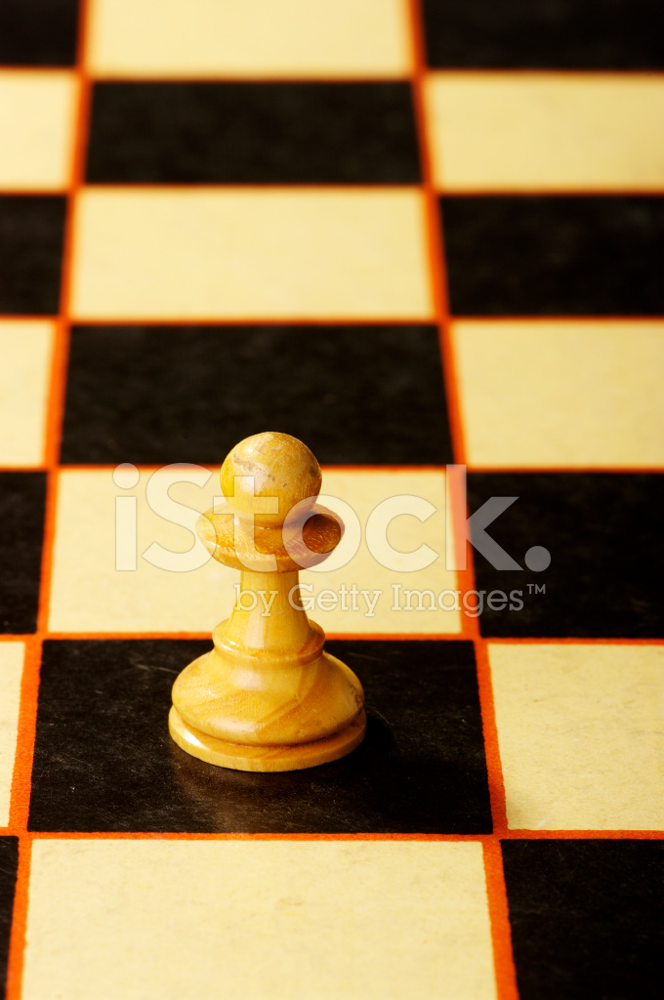

In [136]:
img = dataset["train"][0]["image"]
img


In [133]:
import numpy as np
np.array(img).shape


(1024, 680, 3)

In [ ]:
i2 = img.convert("RGB")
np.array(i2).shape

In [137]:
#### Implement the preprocess_function to convert images to RGB and tokenize them

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

result = preprocess_function(dataset["train"][:2])
list(result.keys())
result["pixel_values"]

tensor([[[[-0.7961, -0.8118, -0.8118,  ..., -0.9137, -0.9216, -0.9294],
          [-0.8118, -0.8196, -0.8196,  ..., -0.9294, -0.9294, -0.9373],
          [-0.8196, -0.8196, -0.8196,  ..., -0.9451, -0.9451, -0.9451],
          ...,
          [-0.6941, -0.3804,  0.4353,  ..., -0.9765, -0.9843, -0.9922],
          [-0.7255, -0.3804,  0.4824,  ..., -0.9608, -0.9686, -0.9843],
          [-0.7098, -0.3098,  0.5451,  ..., -0.9765, -0.9765, -0.9765]],

         [[-0.8902, -0.8980, -0.8902,  ..., -0.9686, -0.9686, -0.9686],
          [-0.8980, -0.8980, -0.8980,  ..., -0.9686, -0.9686, -0.9686],
          [-0.9059, -0.9059, -0.9059,  ..., -0.9765, -0.9765, -0.9765],
          ...,
          [-0.8431, -0.7490, -0.4745,  ..., -0.9922, -0.9922, -1.0000],
          [-0.8745, -0.7961, -0.5294,  ..., -0.9922, -0.9922, -0.9922],
          [-0.8588, -0.7725, -0.4902,  ..., -1.0000, -1.0000, -0.9922]],

         [[-0.9373, -0.9373, -0.9294,  ..., -0.9843, -0.9843, -0.9922],
          [-0.9451, -0.9373, -

In [134]:
#### Process the entire dataset using the preprocess_function
prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 56
    })
})

In [ ]:
dataset["train"][40]

In [ ]:
prepared_dataset["train"][40]

In [138]:
##### Step 6: Define the training arguments and Trainer
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="../../data/results",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    dataloader_pin_memory=False # silence the warning on MacOS Apple Silicon
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
)


In [139]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics

{'test_loss': 1.8076465129852295,
 'test_model_preparation_time': 0.0023,
 'test_runtime': 3.0519,
 'test_samples_per_second': 18.349,
 'test_steps_per_second': 1.311}

In [140]:
predictions.predictions

array([[-0.04027326, -0.08792641, -0.06737381,  0.00827732, -0.18327385,
        -0.00522058],
       [-0.05112623, -0.0678153 , -0.09325265,  0.06281548, -0.03190264,
         0.09688525],
       [ 0.01724016, -0.08392254, -0.08582117,  0.04527064, -0.19739342,
         0.08134419],
       [-0.04774455, -0.02371268, -0.07888365,  0.01529066, -0.06693827,
        -0.02542732],
       [-0.10929185, -0.13670257, -0.09658474,  0.00755547, -0.14180195,
         0.04566569],
       [-0.13464811, -0.11852504, -0.09017657, -0.0006224 , -0.1451518 ,
        -0.03983936],
       [-0.16783172,  0.03715749, -0.05896761, -0.12009161,  0.02755309,
        -0.07491088],
       [-0.13470751,  0.0838926 , -0.14358099, -0.131487  ,  0.07032748,
        -0.00326415],
       [-0.04177114, -0.12688792,  0.01101249,  0.01176163, -0.06414704,
         0.07229515],
       [-0.16863401, -0.03127767,  0.10092701, -0.2064402 ,  0.21359254,
        -0.09514591],
       [-0.06993356, -0.02280898, -0.12104881, -0.

In [141]:
##### Step 8: Evaluate the model performance
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")


[1 3 0 3 4 2 2 1 2 2 3 3 4 3 4 5 1 0 2 4 0 1 3 5 2 2 3 0 2 4 2 2 0 5 1 1 5
 2 5 3 3 2 4 5 4 1 5 1 0 2 3 5 5 2 1 5]
[3 5 5 3 5 3 1 1 5 4 3 5 3 1 5 3 5 2 5 1 3 3 3 2 4 5 5 5 5 5 1 4 5 2 5 3 1
 3 4 5 1 5 5 1 0 3 4 5 2 4 5 5 3 0 3 4]


In [142]:

incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)


Incorrectly classified sample indices: [ 0  1  2  4  5  6  8  9 11 12 13 14 15 16 17 18 19 20 21 23 24 25 26 27
 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 52
 53 54 55]
Predicted labels for incorrect samples: [3 5 5 5 3 1 5 4 5 3 1 5 3 5 2 5 1 3 3 2 4 5 5 5 5 5 1 4 5 2 5 3 1 3 4 5 1
 5 5 1 0 3 4 5 2 4 5 3 0 3 4]
True labels for incorrect samples: [1 3 0 4 2 2 2 2 3 4 3 4 5 1 0 2 4 0 1 5 2 2 3 0 2 4 2 2 0 5 1 1 5 2 5 3 3
 2 4 5 4 1 5 1 0 2 3 5 2 1 5]


In [ ]:
incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

In [ ]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

In [ ]:
!conda install seaborn -y

In [ ]:
!conda install -c conda-forge scikit-learn -y

In [ ]:
!conda install matplotlib -y

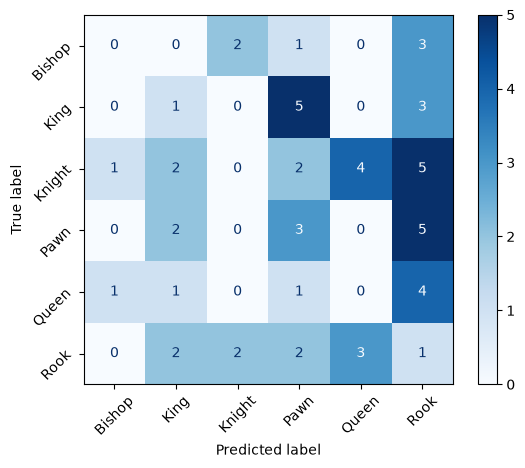

In [143]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = trainer.predict(prepared_dataset["test"])
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
disp.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
disp.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
plt.show()

#import seaborn as sns

#cm = confusion_matrix(true_labels, predicted_labels)
#label_names = dataset["train"].features["label"].names

#plt.figure(figsize=(10, 8))
#sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#            xticklabels=label_names, yticklabels=label_names)

#plt.xlabel('Predicted Label')   
#plt.ylabel('True Label')
#plt.title('Confusion Matrix')
#plt.show()

In [ ]:
import sklearn
sklearn.__version__

### Fine-tuning this model

In [ ]:
import evaluate


In [144]:
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [145]:
##### Training the model with new dataset (fine-tuning)
import os
#os.environ["TENSORBOAD_LOGGING_DIR"] = "../../data/logs/vit-finetuned-chessman2"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../../data/models/vit-finetuned-chessman-aug1",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    logging_dir="../../data/logs/vit-finetuned-chessman-aug1",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.760700,1.713368,0.381818
2,1.649800,1.599992,0.400000
3,1.503000,1.457763,0.490909
4,1.336700,1.303141,0.581818
5,1.174200,1.155401,0.672727
6,1.015300,1.026745,0.709091
7,0.876100,0.894914,0.781818
8,0.757500,0.804962,0.800000
9,0.654500,0.720312,0.781818
10,0.568900,0.654051,0.836364


TrainOutput(global_step=476, training_loss=0.8164428672870668, metrics={'train_runtime': 401.8864, 'train_samples_per_second': 109.981, 'train_steps_per_second': 6.967, 'total_flos': 5.82295684943831e+17, 'train_loss': 0.8164428672870668, 'epoch': 17.0})

In [ ]:

trainer.save_model("../../data/models/vit-finetuned-chessman5")

In [146]:
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


{'test_loss': 0.48999717831611633,
 'test_accuracy': 0.8571428571428571,
 'test_runtime': 2.575,
 'test_samples_per_second': 21.748,
 'test_steps_per_second': 1.553}

In [147]:
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

[1 3 0 3 4 2 2 1 2 2 3 3 4 3 4 5 1 0 2 4 0 1 3 5 2 2 3 0 2 4 2 2 0 5 1 1 5
 2 5 3 3 2 4 5 4 1 5 1 0 2 3 5 5 2 1 5]
[1 3 0 3 4 2 2 4 2 2 3 3 4 3 4 5 4 0 2 0 0 1 3 5 2 2 3 0 2 4 2 2 0 5 4 0 5
 2 5 3 0 2 4 5 4 1 5 1 0 2 0 5 5 2 4 5]


In [148]:
incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

true_label_names = dataset["test"].features["label"]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)

incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

Incorrectly classified sample indices: [ 7 16 19 34 35 40 50 54]
Predicted labels for incorrect samples: [4 4 0 4 0 0 0 4]
True labels for incorrect samples: [1 1 4 1 1 3 3 1]
Predicted label names for incorrect samples: ['Queen', 'Queen', 'Bishop', 'Queen', 'Bishop', 'Bishop', 'Bishop', 'Queen']
True label names for incorrect samples: ['King', 'King', 'Queen', 'King', 'King', 'Pawn', 'Pawn', 'King']


In [ ]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

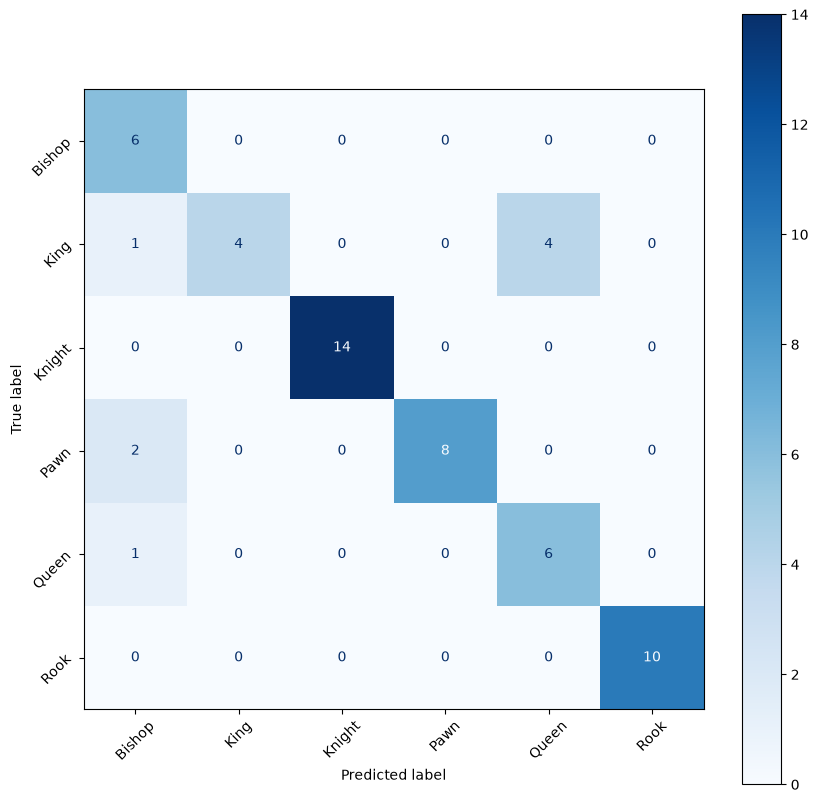

In [149]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def plot_confusion_matrix(labels, pred_labels):

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(1, 1, 1)
    cm = confusion_matrix(labels, pred_labels)
    cm = ConfusionMatrixDisplay(cm, display_labels=range(6))
    cm.plot(values_format='d', cmap='Blues', ax=ax)
    cm.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
    cm.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
    plt.show()

plot_confusion_matrix(true_labels, predicted_labels)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_labels, predicted_labels)
label_names = dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
trainer.save_model("../../data/models/vit-finetuned-chessman-final2")

In [ ]:
import matplotlib.pyplot as plt

num_plots = min(5, len(incorrect_samples))

plt.figure(figsize=(10, 5))
for i in range(num_plots):
    idx = incorrect_indices[i]
    # Assuming the dataset returns a dictionary with 'image' and 'label'
    sample = test_dataset[idx] 
    image = sample['image'] 
    
    plt.subplot(1, num_plots, i + 1)
    plt.imshow(image)
    plt.title(f"True: {true_label_names_incorrect[i]}\nPred: {incorrect_label_names[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

---

### Exercise: Try fine-tuning ViT model for fatigue dataset (from Kaggle)
The link to the dataset: https://www.kaggle.com/datasets/rihabkaci99/fatigue-dataset/

Try using `mo-thecreator/vit-Facial-Expression-Recognition` and `trpakov/vit-face-expression` models 
from HuggingFace as the initial checkpoint

In [ ]:
ls ../data/Human_Face_Expression_Fatigue/

In [ ]:
#### Step 1: Load your custom dataset
from datasets import load_dataset
dataset = load_dataset("../data/Human_Face_Expression_Fatigue")
dataset

In [ ]:
#### Step 2: Split the dataset into training, validation and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_test["train"]
print(train_dataset)

test_val = train_test["test"].train_test_split(test_size=0.5)
val_dataset = test_val["train"]
test_dataset = test_val["test"]

from datasets import DatasetDict
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
dataset

num_classes = dataset["train"].features["label"].num_classes
num_classes


In [ ]:
#### Step 3: Use a pretrained model
checkpoint = "mo-thecreator/vit-Facial-Expression-Recognition"
model = AutoModelForImageClassification.from_pretrained(
    checkpoint, 
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)

In [ ]:
##### Step 4: Preprocess the images suited to the model
from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint, use_fast=True)

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

In [ ]:
##### Step 5: Setup evaluation metrics and callbacks (optional)
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [ ]:
##### Step 6: Initialize the Trainer and define the training arguments, train the model
import os
os.environ["TENSORBOARD_LOGGING_DIR"] = "../data/logs/vit-facial-expression-fatigue"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../data/vit-facial-expression-fatigue",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    #logging_dir="../../data/logs/vit-facial-expression-fatigue",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

In [ ]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


In [ ]:
##### Step 8: Evaluate the model performance with test set and visualize the results

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

cm = confusion_matrix(true_labels, predicted_labels)
label_names = prepared_dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
#### Step 9: Save the fine-tuned model
trainer.save_model("../data/models/vit-finetuned-human-face-expression-fatigue")

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir ../data/logs/vit-facial-expression-fatigue

---

In [ ]:
g = model.parameters()

In [ ]:
model.get_memory_footprint() / (1024 * 1024)

In [ ]:
total = 0
for p in model.parameters():
    total += p.numel()

total / (1000 * 1000)

---